## Quantum Programming

### Nicolas Ollinger and Ioan Todinca
<img style="width:15%; height: auto;" src="img/lifo.png">

#### M2 Computer Science, S9 2026/2027


## Multilingual hybrid teaching

This course has been adapted for an <b class="cool">international audience</b>.
 - students in **M2 ARIAS** at the University of Orléans;
 - **GPEX** students in the Minerve programme at the University of Orléans;
 - students from partner universities in the **Athena** programme with assessment;
 - auditing students from partner universities in the **Athena** programme.

 Lectures are offered to all these audiences in hybrid mode on  the lecture is delivered in English with a livestream on **Teams**.
 The course materials are available:
  - in **English** send by email to Athena students;
  - in **French** on the course <b class="cool">Celene page</b>.


## Course description

This course offers an introduction to quantum computing through the <b class="cool">programming of quantum circuits</b>.

Students are invited to <b class="cool">build circuits</b> and to <b class="cool">simulate their execution</b> in order to understand what current quantum technology offers and how it differs from classical models of <b class="cool">Boolean computation</b>. This experimental approach will then make it possible to present more precisely the algorithmic promises and the current challenges of this technology.

Assessment consists of a final exam and <b class="cool">hands‑on tasks to be carried out on a computer</b> and submitted at the end of the lab sessions.


## Battle plan

$$
\begin{align*}
\textbf{ARIAS}\quad 10\mathrm{h~} &\textbf{lecture} + 10\mathrm{h~} \textbf{tutorials} + 10\mathrm{h~} \textbf{labs}\\
\textbf{GPEX}\quad 10\mathrm{h~} &\textbf{lecture} + \phantom{1}6\mathrm{h~} \textbf{tutorials} + \mbox{self‑guided labs}\\
\textbf{Athena}\quad 10\mathrm{h~} &\textbf{lecture} + \mbox{translated documents and online sessions}
\end{align*}
$$

| Session | Instructor | Duration | Programme |
| :-- | :-- | :-: | :-- |
| L1 | N. Ollinger | __2h__ | *Quantum circuits and reversible computation* |
| L2 | N. Ollinger | __2h__ | *Circuits and quantum computation, the Bernstein–Vazirani algorithm* |
| L3 | I. Todinca | __2h__ | *Quantum computing, important algorithms* |
| L4 | I. Todinca | __2h__ | *Grover's quantum search algorithm* |
| L5 | I. Todinca | __2h__ | *Quantum computing for computer scientists!* |


## Assessment (University of Orléans)

$$
\textbf{UE} = \frac13 \textbf{CC} + \frac23 \textbf{CT}
$$

$\textbf{CC}$: Jupyter notebooks to be completed and submitted on the Celene page of the course [Celene](https://celene.univ-orleans.fr/course/view.php?id=12816).

Exercises to be done using Python and the [Qiskit](https://qiskit.org) library (v1.2)


## Quantum circuits?

Today’s (or perhaps tomorrow’s?) quantum computers are used as _coprocessors_: one applies a <b class="cool">unitary transformation</b> to a <b class="cool">register of qubits</b> initially all set to zero, and then performs <b class="cool">measurements</b> on its state.

<b class="cool">Unitary transformations</b> are encoded as circuits, and quantum programming looks like <b class="cool">assembly-level programming</b>.

Quantum programming offers a <b class="cool">new form of parallelism</b>.


<img style="width:100%; height: auto;" src="img/quito1.png">

<img style="width:100%; height: auto;" src="img/quito2.png">

<img style="width:100%; height: auto;" src="img/quito3.png">

## Illustrated with Qiskit

This course is also a downloadable Jupyter notebook that can be run in the cloud. Its examples are built using the __[Qiskit](https://qiskit.org)__ library, which lets you manipulate quantum circuits in Python:
  1. <b class="cool">build</b> circuits;
  2. <b class="cool">run</b> these circuits locally in a simulator;
  3. <b class="cool">run</b> these circuits on quantum processors (e.g., IBM);
  4. <b class="cool">analyse</b> the execution results.


### Let's import what we need


In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit.providers.basic_provider import BasicProvider
from qiskit_aer import UnitarySimulator
from qiskit.visualization import plot_histogram
import qiskit.quantum_info as qi
from math import sqrt
import numpy as np

# A full-circuit simulator
sim = BasicProvider().get_backend('basic_simulator')

# A simulator that computes the transformation matrix
usim = UnitarySimulator() 

# Display a circuit
def draw_circ(circ): display(circ.draw(output='mpl'))
    
# Compute the matrix of a circuit
def mat_circ(circ): return usim.run(circ).result().get_unitary()

def show(circ):
    draw_circ(circ)
    display(mat_circ(circ).draw('latex'))


But wait... <b class="cool">What is a quantum circuit?</b>


# A dash of theory...


### Classical Boolean circuits

Since Shannon’s work at the end of the 1930s, <b class="cool">Boolean algebra</b> and the binary system underpin digital electronics.

A <b class="cool">classical memory</b> register stores a vector of <b class="cool">bits</b>, each taking one of two values: \$0\$ or \$1\$. The bits are independent; with \$n\$ bits, one value among \$2^n\$ is stored.

<b class="cool">Logic gates</b> implementing logical functions ($\operatorname{AND}$, $\operatorname{OR}$, $\operatorname{NOT}$) make it possible to <b class="cool">compute efficiently</b> any Boolean function $f : \left\{0,1\right\}^n \longrightarrow \left\{0,1\right\}^m$.

### A qubit

A <b class="cool">quantum memory</b> register is a <b class="cool">finite discrete quantum system</b> made up of <b class="cool">qubits</b>.

A <b class="cool">quantum bit</b> is a superposition of $0$ and $1$:
$$
\alpha\,\left|0\right> + \beta\,\left|1\right> \quad\text{with}\quad \alpha, \beta \in \mathbb{C}
\quad\text{such that}\quad |\alpha|^2+|\beta|^2 = 1
$$

For example $\left|0\right>$, or $\tfrac{1}{\sqrt{2}}\left(\left|0\right>+\left|1\right>\right)$.


### Multiple qubits

A register of <b class="cool">$n$ qubits</b> is a superposition over all bit strings in $\{0,1\}^n$, each with a complex amplitude.

$$
\left|\varphi\right> = \sum_{x\in\{0,1\}^n} \alpha_x\left|x\right> \quad\mbox{such that}\quad \sum_{x\in\{0,1\}^n}  |\alpha_x|^2 = 1
$$

For example $\tfrac12\left|1000\right>+\tfrac12\left|0100\right>+\tfrac12\left|0010\right>+\tfrac12\left|0001\right>$


### Tensor product

The <b class="cool">composition</b> of two quantum registers is given by the <b class="cool">tensor product</b>.
In particular, for basis states one has $\left|x\right> \otimes \left|y\right> = \left|xy\right>$.

$$
\left|1\right> \otimes \frac{1}{\sqrt{2}}\left(\left|0\right>+\left|1\right>\right) =
\frac{1}{\sqrt{2}}\left(\left|10\right>+\left|11\right>\right)
$$

Unlike the classical case, not every register is decomposable into subregisters!

Example of an <b class="cool">entangled</b> state: $\tfrac{1}{\sqrt{2}}\left(\left|00\right>+\left|11\right>\right)$.


## Quantum measurement (observation)

<img style="width=100%; height=auto; margin: auto" src="img/mesure.png" />


## Quantum measurement of a specific qubit

Starting from a state $\left|\varphi\right> = \sum_x \alpha_x\,\left|x\right>$, measuring the $i$‑th qubit in the computational basis yields a value $r\in\{0,1\}$ with probability $p_r$, and the system changes state as follows:

$$
\sum_{x\in\{0,1\}^n} \alpha_x\,\left|x\right> \underset{\phantom{blop}p_r\phantom{blop}}{\longrightarrow}
\frac{1}{\sqrt{p_r}} \sum_{x\in\{0,1\}^n \mid x_i = r} \alpha_x\,\left|x\right>
$$


$$
\mbox{with}\quad p_r = \sum_{x\in\left\{0,1\right\}^n | x_i = r}|\alpha_x|^2
$$

## Unitary evolution

In the absence of measurement, when isolated, the state of a quantum system evolves <b class="cool">unitarily</b>.

$$
U : \mathbb{C}^{\{0,1\}^n} \rightarrow \mathbb{C}^{\{0,1\}^n}
$$

1. $U$ is linear:
$$
U\left(\alpha\left|\varphi\right>+\beta\left|\psi\right>\right) = \alpha\,U\left|\varphi\right>+\beta\,U\left|\psi\right>\quad;
$$
2. $U$ preserves the norm: $\left\| U\left|\varphi\right> \right\| = \left\| \left|\varphi\right> \right\|$.


## Quantum gate

A quantum circuit encodes a <b class="cool">unitary transformation</b> applied to a quantum state. Quantum gates are therefore reversible, with as many qubits at input as at output.
- sequential composition: matrix product;
- parallel composition: tensor product.

Which <b class="cool">universal gate family?</b>


## Single-qubit gates

$$
\begin{array}{clclcl}
X :& \left|0\right> \mapsto \left|1\right> & H :& \left|0\right> \mapsto \tfrac{\left|0\right>+\left|1\right>}{\sqrt2}  & R_\theta :& \left|0\right> \mapsto \left|0\right>\\
   & \left|1\right> \mapsto \left|0\right> &    & \left|1\right> \mapsto \tfrac{\left|0\right>-\left|1\right>}{\sqrt2} &  & \left|1\right> \mapsto e^{i\theta}\left|1\right> \\
\end{array}
$$


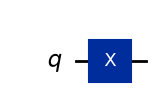

<IPython.core.display.Latex object>

In [3]:
from math import pi
circuit = QuantumCircuit(1)
# replace x here with h or t (=r(pi/4)) or sx (sqrt(x))
circuit.x(0)
show(circuit)


## Controlled gates

$$
\begin{array}{cl}
CX :& \left|00\right> \mapsto \left|00\right> \\
   & \left|01\right> \mapsto \left|01\right> \\
   & \left|10\right> \mapsto \left|11\right> \\
   & \left|11\right> \mapsto \left|10\right> \\
\end{array}
$$


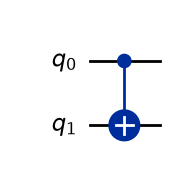

<IPython.core.display.Latex object>

In [4]:
circuit = QuantumCircuit(2)
circuit.cx(0,1)
show(circuit)

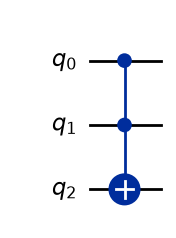

<IPython.core.display.Latex object>

In [5]:
circuit = QuantumCircuit(3)  
circuit.ccx(0,1,2)
show(circuit)

## Universality

The gate family $\left\{H, CX, R_\theta\right\}_{\theta\in[0,2\pi[}$ is <b class="cool">universal</b> for unitary transformations.

The gate family $\left\{H, CX, R_{\frac{\Pi}4}\right\}$ is <b class="cool">approximately universal</b> for unitary transformations: it implements them within a desired error $\varepsilon$.

The <b class="cool">Solovay–Kitaev theorem</b> ensures that any approximately universal gate family achieves such approximations <b class="cool">efficiently</b>.


## Compatibility

Every classical function $f : \{0,1\}^n \rightarrow \{0,1\}^m$ is simulated by a quantum circuit of similar size.

$$
\begin{array}{ccccc}
U_f &:& \mathbb{C}^{\{0,1\}^{m+n}} & \rightarrow & \mathbb{C}^{\{0,1\}^{m+n}}\\
    & & \left|x,y\right> & \mapsto & \left|x, f(x)\oplus y \right>
\end{array}
$$

This is a result from <b class="cool">reversible computation</b>.


## Quantum algorithm

Most <b class="cool">quantum algorithms</b> follow the principle below:
1. create a relevant superposition of qubits from $\left|00\cdots 0\right>$;
2. perform a <b class="cool">classical computation in parallel</b> over the superposition of inputs;
3. apply a <b class="cool">relevant quantum transformation</b>;
4. observe the result by <b class="cool">measurement(s)</b>.


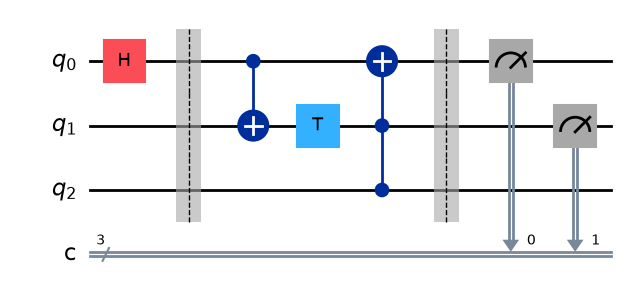

In [19]:
circ = QuantumCircuit(3,3)  ## 3 qubits + 3 classical bits
for i in range(1): circ.h(i) ## put |00> + |01> + |10> + |11> on |q0 q1>
circ.barrier()
circ.cx(0,1)
circ.t(1)
circ.ccx(1,2,0)
circ.barrier()
for i in range(2): circ.measure(i,i)
draw_circ(circ)

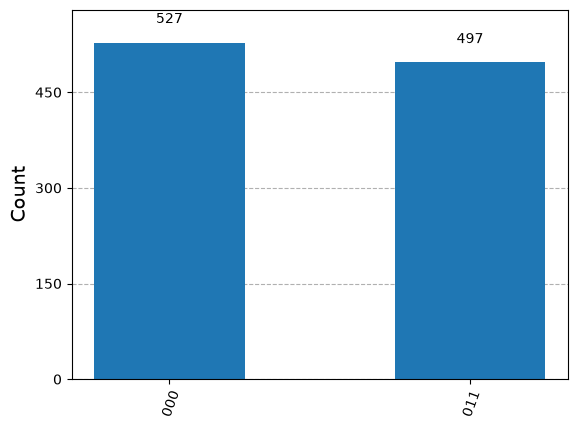

In [20]:
res = sim.run(circ, shots=1024).result()
display(plot_histogram(res.get_counts()))

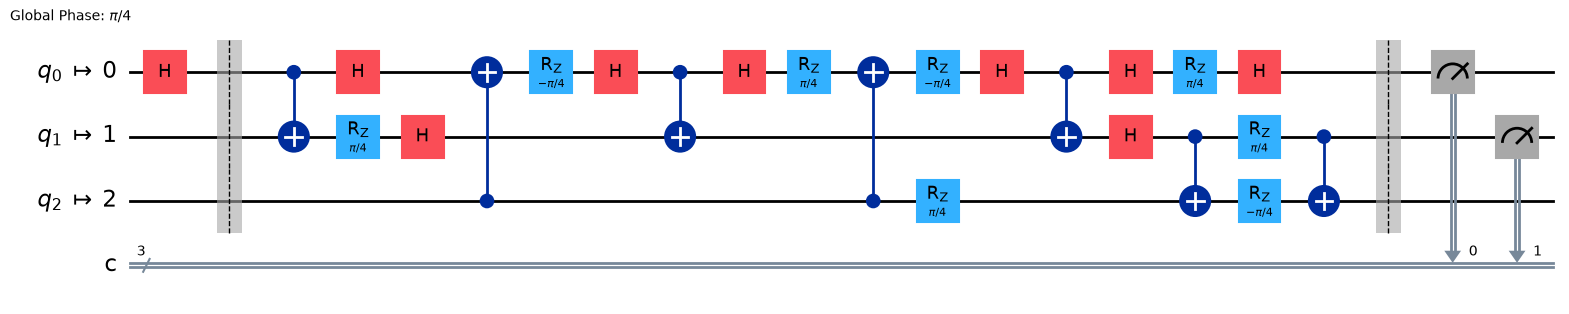

In [21]:
res=transpile(circ,basis_gates=['h','cx', 'rz'], coupling_map = [[0,1],[1,2],[2,0]], optimization_level=1)
draw_circ(res) 

# Further reading

P. Arrighi and S. Perdrix. _Modèles de calcul quantique_. in __[Informatique Mathématique, une photographie en 2016](https://www.gdr-ifm.fr/wp-content/uploads/2020/04/recueilEJCIM16-1.pdf)__. CNRS Éditions.


M.A. Nielsen and I.L. Chuang. _Quantum Computation and Quantum Information_. Cambridge Univ. Press, 2000.

__[IBM Q Experience.](https://quantum-computing.ibm.com)__

__[Introduction to Coding Quantum Algorithms: A Tutorial Series Using Qiskit](https://arxiv.org/abs/1903.04359)__
